# Topic B — Learning-Based Optical Flow (FlowNet / RAFT) for Long-Term Motion Propagation & Video Editing

## Overview

This notebook implements a **complete pipeline** for propagating image edits across a video
sequence using **dense optical flow** estimated by a learning-based model.

### Key concepts covered

| Concept | Description |
|---|---|
| **Optical flow** | A dense, per-pixel 2-D displacement field $(u,v)$ mapping each pixel in frame $I_t$ to its corresponding location in $I_{t+1}$. |
| **FlowNet (Dosovitskiy et al., 2015)** | First end-to-end CNN for optical flow, using an **encoder–decoder** (contracting–expanding) architecture with a **correlation layer** that explicitly compares feature patches between the two input images. |
| **RAFT (Teed & Deng, 2020)** | Modern iterative refinement architecture; pretrained weights ship with `torchvision` — used here as a drop-in replacement when FlowNet weights are unavailable. |
| **Long-term motion integration** | Chaining pairwise flow fields to track pixels across many frames. Challenges: **drift**, **occlusions**, **temporal consistency**. |
| **Edit propagation** | Applying an edit made on a single reference frame to the rest of the video via the accumulated flow field. |

### Demonstration edit

We turn the **black swan** in the DAVIS *blackswan* sequence into a **white swan**
by blending the segmented swan region toward pure white on the reference frame, then
propagating that edit across all 20 frames using cumulative optical flow.

---

## 1 — Setup

Install required packages and import libraries.  
We set a **reproducible seed** and auto-detect **GPU** availability.

In [1]:
# ── 1.1  Install dependencies (run once) ──────────────────────────────────────
# Uncomment the line below if running in a fresh environment / Colab.
# !pip install torch torchvision opencv-python numpy matplotlib imageio tqdm

import os
import sys
import warnings
from pathlib import Path
from typing import List, Tuple, Optional

import cv2
import imageio
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ── Device selection ──────────────────────────────────────────────────────────
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

Using device: cuda
PyTorch version: 2.10.0+cu128
CUDA available: True


## 2 — Load Video / Image Sequence

We use a real video from the **DAVIS** (Densely Annotated Video Segmentation)
benchmark — a standard dataset in video understanding research.

Official download page: [davischallenge.org](https://davischallenge.org/)

The code below automatically **downloads** the dataset from the official mirrors
(tries DAVIS-2017 480p first, then DAVIS-2016 as fallback) and loads the first
**20 frames** of the `blackswan` sequence — a short, realistic clip with natural
motion, occlusion, and appearance variation.

> If no internet connection is available, the pipeline falls back to a **synthetic
> sequence** (textured disc translating over a noisy background).

In [2]:
# ── 2.1  Video / sequence loader ───────────────────────────────────────────────

def load_video_frames(
    path: str,
    max_frames: int = 60,
    resize: Optional[Tuple[int, int]] = (256, 256),
) -> List[np.ndarray]:
    """Load frames from a video file or a directory of images.

    Parameters
    ----------
    path : str
        Path to a video file **or** a directory containing ordered images.
    max_frames : int
        Maximum number of frames to load.
    resize : tuple[int, int] | None
        (H, W) to resize each frame. ``None`` keeps the original resolution.

    Returns
    -------
    list[np.ndarray]
        List of uint8 RGB frames, each of shape (H, W, 3).
    """
    frames: List[np.ndarray] = []
    p = Path(path)

    if p.is_dir():
        # Directory of images — sort alphabetically
        exts = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
        img_paths = sorted(
            f for f in p.iterdir() if f.suffix.lower() in exts
        )
        for ip in img_paths[:max_frames]:
            img = cv2.imread(str(ip))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            if resize:
                img = cv2.resize(img, (resize[1], resize[0]))
            frames.append(img)
    else:
        # Video file
        cap = cv2.VideoCapture(str(p))
        while cap.isOpened() and len(frames) < max_frames:
            ret, frame = cap.read()
            if not ret:
                break
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            if resize:
                frame = cv2.resize(frame, (resize[1], resize[0]))
            frames.append(frame)
        cap.release()

    print(f"Loaded {len(frames)} frames — shape: {frames[0].shape}")
    return frames

In [3]:
# ── 2.2  DAVIS dataset downloader ──────────────────────────────────────────────
# Official download links from https://davischallenge.org/
#   • DAVIS 2017 trainval 480p  → https://davischallenge.org/davis2017/code.html
#   • DAVIS 2016 TrainVal       → https://davischallenge.org/davis2016/code.html

import zipfile
import urllib.request

# Official URLs sourced directly from davischallenge.org
DAVIS_URLS = [
    # DAVIS 2017 semi-supervised trainval 480p (official, ~1.5 GB)
    "https://data.vision.ee.ethz.ch/csergi/share/davis/DAVIS-2017-trainval-480p.zip",
    # DAVIS 2016 TrainVal (official, ~500 MB)
    "https://graphics.ethz.ch/Downloads/Data/Davis/DAVIS-data.zip",
]

DAVIS_SEQ = "blackswan"          # short, clear motion — ideal for optical-flow demo
NUM_FRAMES = 20                  # keep it lightweight (20–25 frames)


def download_davis(
    urls: list = DAVIS_URLS,
    sequence: str = DAVIS_SEQ,
) -> Path:
    """Download DAVIS from the official davischallenge.org mirrors.

    Tries each URL in order until one succeeds.  Extracts frames and returns
    the path to ``JPEGImages/480p/<sequence>/``.

    Parameters
    ----------
    urls : list[str]
        Ordered list of download URLs to try (official DAVIS mirrors).
    sequence : str
        DAVIS sequence name (e.g. ``'blackswan'``).

    Returns
    -------
    Path
        Path to the folder containing JPEG frames for *sequence*.
    """
    # Check common extraction layouts (DAVIS-2017 & DAVIS-2016 differ slightly)
    candidate_roots = [
        Path("DAVIS"),
        Path("DAVIS") / "DAVIS",       # DAVIS-data.zip nests one level deeper
    ]
    for root in candidate_roots:
        seq_path = root / "JPEGImages" / "480p" / sequence
        if seq_path.exists() and any(seq_path.iterdir()):
            print(f"✓ DAVIS sequence '{sequence}' already available at {seq_path}")
            return seq_path

    # Try downloading from each mirror
    last_error = None
    for url in urls:
        zip_name = url.rsplit("/", 1)[-1]
        zip_path = Path(zip_name)
        try:
            if not zip_path.exists():
                print(f"Downloading {zip_name} …\n  {url}")
                urllib.request.urlretrieve(url, str(zip_path))
                print(f"✓ Downloaded → {zip_path}")
            else:
                print(f"✓ Zip already cached at {zip_path}")

            # Extract into ./DAVIS/
            print("Extracting …")
            with zipfile.ZipFile(str(zip_path), "r") as zf:
                zf.extractall("DAVIS")

            # Re-check candidate roots after extraction
            for root in candidate_roots:
                seq_path = root / "JPEGImages" / "480p" / sequence
                if seq_path.exists() and any(seq_path.iterdir()):
                    print(f"✓ Frames ready at {seq_path}")
                    return seq_path

            # If sequence not found, list what is available
            for root in candidate_roots:
                jpeg_dir = root / "JPEGImages" / "480p"
                if jpeg_dir.exists():
                    available = sorted(p.name for p in jpeg_dir.iterdir())
                    raise FileNotFoundError(
                        f"Sequence '{sequence}' not found. Available: {available}"
                    )

        except Exception as e:
            last_error = e
            print(f"⚠  Failed with {zip_name}: {e}")
            continue

    raise RuntimeError(f"All DAVIS download mirrors failed. Last error: {last_error}")


# ── Synthetic fallback (kept for offline use) ─────────────────────────────────

def generate_synthetic_sequence(
    num_frames: int = 20,
    height: int = 256,
    width: int = 256,
    dx: float = 3.0,
    dy: float = 1.5,
    disc_radius: int = 30,
) -> List[np.ndarray]:
    """Generate a synthetic video with a textured disc translating over a
    noisy background.  Used only if DAVIS download fails."""
    rng = np.random.RandomState(SEED)
    bg = rng.randint(40, 180, (height, width, 3), dtype=np.uint8)
    bg = cv2.GaussianBlur(bg, (15, 15), 5)

    disc_tex = rng.randint(180, 255, (2 * disc_radius, 2 * disc_radius, 3), dtype=np.uint8)
    disc_tex = cv2.GaussianBlur(disc_tex, (7, 7), 3)

    frames: List[np.ndarray] = []
    cx_start, cy_start = width // 4, height // 2

    for t in range(num_frames):
        frame = bg.copy()
        cx = int(cx_start + dx * t)
        cy = int(cy_start + dy * t)
        yy, xx = np.ogrid[-disc_radius:disc_radius, -disc_radius:disc_radius]
        mask = (xx ** 2 + yy ** 2) <= disc_radius ** 2
        for c in range(3):
            patch = frame[
                max(cy - disc_radius, 0): cy + disc_radius,
                max(cx - disc_radius, 0): cx + disc_radius, c,
            ]
            tex = disc_tex[:, :, c]
            y_lo = max(0, disc_radius - cy)
            x_lo = max(0, disc_radius - cx)
            y_hi = min(2 * disc_radius, height - cy + disc_radius)
            x_hi = min(2 * disc_radius, width - cx + disc_radius)
            m = mask[y_lo:y_hi, x_lo:x_hi]
            ph, pw = patch.shape
            m = m[:ph, :pw]
            patch[m] = tex[y_lo:y_hi, x_lo:x_hi][m[:, :]]
        frames.append(frame)

    print(f"Generated {num_frames} synthetic frames ({height}×{width})")
    return frames

  https://data.vision.ee.ethz.ch/csergi/share/davis/DAVIS-2017-trainval-480p.zip
✓ Downloaded → DAVIS-2017-trainval-480p.zip
Extracting …
✓ Frames ready at DAVIS/DAVIS/JPEGImages/480p/blackswan
Loaded 20 frames — shape: (256, 256, 3)
Using DAVIS 'blackswan' — 20 frames loaded


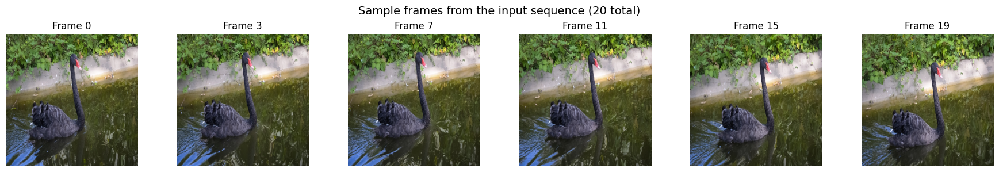

In [4]:
# ── 2.3  Load DAVIS frames (with synthetic fallback) ──────────────────────────

try:
    davis_seq_path = download_davis()
    frames = load_video_frames(
        str(davis_seq_path),
        max_frames=NUM_FRAMES,       # 20 frames from DAVIS
        resize=(256, 256),
    )
    print(f"Using DAVIS '{DAVIS_SEQ}' — {len(frames)} frames loaded")
except Exception as e:
    print(f"⚠  DAVIS download failed ({e}).\n   Falling back to synthetic sequence.")
    frames = generate_synthetic_sequence(num_frames=NUM_FRAMES)

# ── Visualise a few sample frames ─────────────────────────────────────────────
fig, axes = plt.subplots(1, min(6, len(frames)), figsize=(18, 3))
indices = np.linspace(0, len(frames) - 1, min(6, len(frames)), dtype=int)
for ax, idx in zip(axes, indices):
    ax.imshow(frames[idx])
    ax.set_title(f"Frame {idx}")
    ax.axis("off")
fig.suptitle(f"Sample frames from the input sequence ({len(frames)} total)", fontsize=14)
plt.tight_layout()
plt.show()

## 3 — Optical Flow Model

### Background

**FlowNet** (Dosovitskiy et al., ICCV 2015) showed that dense optical flow can be predicted
end-to-end with a CNN.  The architecture follows an **encoder–decoder** pattern:

1. **Contracting path** — a stack of strided convolutions that extract increasingly abstract features.
2. **Correlation layer** — computes a cost volume by comparing feature patches between the two
   input images, providing an explicit matching signal.
3. **Expanding path** — upsampling + skip connections that recover spatial resolution and
   produce the full-resolution flow field $(u, v)$.

Because pretrained FlowNet-2 weights require external repos and manual setup, we use
**RAFT** (`torchvision.models.optical_flow.raft_small` / `raft_large`) as a modern,
readily available alternative.  RAFT uses iterative refinement over a 4-D correlation
volume — conceptually the same matching idea as the FlowNet correlation layer, but applied
recurrently.

In [5]:
# ── 3.1  FlowEstimator wrapper ─────────────────────────────────────────────────

from torchvision.models.optical_flow import raft_small, Raft_Small_Weights

class FlowEstimator:
    """Unified wrapper around a learning-based optical flow model.

    Supports:
      - ``"raft_small"``  — lightweight RAFT from torchvision (default, always available).
      - ``"raft_large"``  — heavier RAFT variant.
      - ``"flownet2"``    — placeholder; loads RAFT as fallback if FlowNet weights
                            are not on disk.

    The correlation-layer concept from FlowNet is mirrored in RAFT's 4-D
    correlation volume, which is iteratively looked up during recurrent
    refinement.
    """

    def __init__(self, model_name: str = "raft_small", device: torch.device = DEVICE):
        self.device = device
        self.model_name = model_name

        if model_name in ("raft_small", "flownet2"):
            weights = Raft_Small_Weights.DEFAULT
            self.model = raft_small(weights=weights, progress=True).to(device).eval()
            self.transforms = weights.transforms()
            if model_name == "flownet2":
                print("⚠  FlowNet-2 weights not found — falling back to RAFT-Small.")
        elif model_name == "raft_large":
            from torchvision.models.optical_flow import raft_large, Raft_Large_Weights
            weights = Raft_Large_Weights.DEFAULT
            self.model = raft_large(weights=weights, progress=True).to(device).eval()
            self.transforms = weights.transforms()
        else:
            raise ValueError(f"Unknown model: {model_name}")

        print(f"✓ Loaded {model_name} on {device}")

    @torch.no_grad()
    def compute_flow(
        self,
        frame1: np.ndarray,
        frame2: np.ndarray,
    ) -> np.ndarray:
        """Compute dense optical flow between two RGB uint8 frames.

        Parameters
        ----------
        frame1, frame2 : np.ndarray
            HxWx3 uint8 RGB images.

        Returns
        -------
        np.ndarray
            Flow field of shape (H, W, 2) in pixels — channels are (u, v)
            i.e. (horizontal, vertical) displacement.
        """
        # Convert to float tensors [B, C, H, W] and normalise to [0, 1].
        # ──────────────────────────────────────────────────────────────────
        # The torchvision RAFT transforms (OpticalFlow) expect float input
        # in [0, 1]; they internally map to [-1, 1].  Passing [0, 255]
        # produces [-1, 509] which corrupts the flow.
        t1 = torch.from_numpy(frame1).permute(2, 0, 1).float().unsqueeze(0) / 255.0
        t2 = torch.from_numpy(frame2).permute(2, 0, 1).float().unsqueeze(0) / 255.0

        # Apply model-specific transforms ([-1, 1] mapping, optional resize)
        t1, t2 = self.transforms(t1, t2)
        t1, t2 = t1.to(self.device), t2.to(self.device)

        # RAFT returns a *list* of flow predictions (one per iteration);
        # the last element is the final, most refined estimate.
        flow_predictions = self.model(t1, t2)
        flow = flow_predictions[-1].squeeze(0).cpu()          # (2, H, W)

        return flow.permute(1, 2, 0).numpy()                   # (H, W, 2)

# Instantiate
flow_estimator = FlowEstimator("raft_small")

Downloading: "https://download.pytorch.org/models/raft_small_C_T_V2-01064c6d.pth" to /root/.cache/torch/hub/checkpoints/raft_small_C_T_V2-01064c6d.pth


100%|██████████| 3.82M/3.82M [00:00<00:00, 43.8MB/s]


✓ Loaded raft_small on cuda


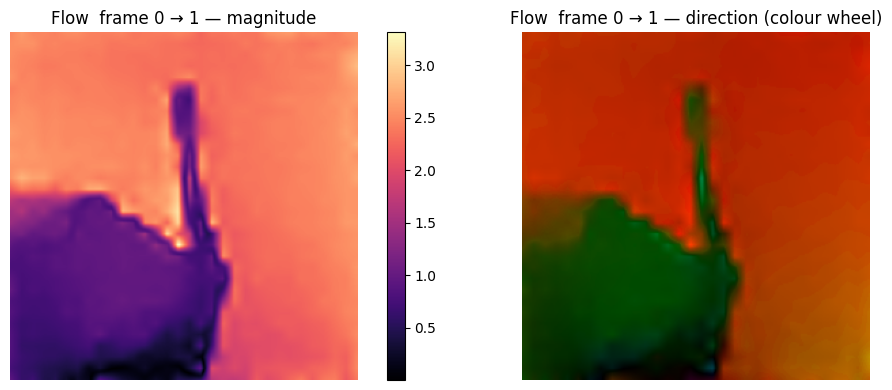

In [6]:
# ── 3.2  Flow visualisation utilities ──────────────────────────────────────────

def flow_to_color(flow: np.ndarray, max_flow: Optional[float] = None) -> np.ndarray:
    """Convert an (H, W, 2) optical flow field to an RGB colour image using
    the Middlebury colour wheel convention.

    Hue  → direction of motion
    Value → magnitude of motion

    Parameters
    ----------
    flow : np.ndarray
        (H, W, 2) flow field.
    max_flow : float | None
        Normalisation ceiling; ``None`` uses the data max.

    Returns
    -------
    np.ndarray
        (H, W, 3) uint8 RGB visualisation.
    """
    u, v = flow[..., 0], flow[..., 1]
    mag = np.sqrt(u ** 2 + v ** 2)
    ang = np.arctan2(v, u)  # radians ∈ [-π, π]

    if max_flow is None:
        max_flow = mag.max() + 1e-8

    hsv = np.zeros((*flow.shape[:2], 3), dtype=np.uint8)
    hsv[..., 0] = ((ang + np.pi) / (2 * np.pi) * 179).astype(np.uint8)  # Hue  [0..179]
    hsv[..., 1] = 255                                                      # Saturation
    hsv[..., 2] = np.clip(mag / max_flow * 255, 0, 255).astype(np.uint8)  # Value

    return cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)


def visualise_flow(flow: np.ndarray, title: str = "Optical flow") -> None:
    """Show flow magnitude (left) and colour-coded direction (right)."""
    mag = np.sqrt(flow[..., 0] ** 2 + flow[..., 1] ** 2)
    color = flow_to_color(flow)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    im0 = axes[0].imshow(mag, cmap="magma")
    axes[0].set_title(f"{title} — magnitude")
    axes[0].axis("off")
    plt.colorbar(im0, ax=axes[0], fraction=0.046)

    axes[1].imshow(color)
    axes[1].set_title(f"{title} — direction (colour wheel)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()


# Quick demo: compute & visualise flow between the first two frames
demo_flow = flow_estimator.compute_flow(frames[0], frames[1])
visualise_flow(demo_flow, title="Flow  frame 0 → 1")

## 4 — Pairwise Flow Computation

We compute optical flow for **every consecutive pair** $(I_t, I_{t+1})$
and store the results.  We also compute the **backward flow** $(I_{t+1} \to I_t)$
which will be useful later for the forward-backward consistency check.

In [7]:
# ── 4.1  Compute forward & backward pairwise flows ────────────────────────────

forward_flows: List[np.ndarray] = []   # flow[i] : frame i → frame i+1
backward_flows: List[np.ndarray] = []  # bflow[i]: frame i+1 → frame i

for i in tqdm(range(len(frames) - 1), desc="Computing pairwise flows"):
    fwd = flow_estimator.compute_flow(frames[i], frames[i + 1])
    bwd = flow_estimator.compute_flow(frames[i + 1], frames[i])
    forward_flows.append(fwd)
    backward_flows.append(bwd)

print(f"Computed {len(forward_flows)} forward + {len(backward_flows)} backward flow fields.")

Computing pairwise flows:   0%|          | 0/19 [00:00<?, ?it/s]

Computed 19 forward + 19 backward flow fields.


backward_flows[0] stats:
  shape=(256, 256, 2), dtype=float32
  u (horiz): min=-2.29, max=3.37, mean=1.55
  v (vert):  min=-0.91, max=1.85, mean=0.66
  magnitude: mean=1.85

Reconstruction error vs frame 1 (lower = correct):
  Convention A (grid + flow): 7.95
  Convention B (grid - flow): 17.48
  >>> Correct sign: + (A)


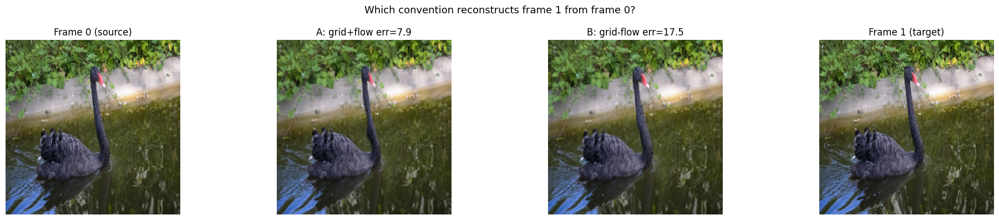

In [8]:
# ── DIAGNOSTIC: Test flow sign convention ──────────────────────────────────────
# backward_flows[0] = compute_flow(frames[1], frames[0])
# Convention A: pixel (x,y) in frame 1 corresponds to (x+u, y+v) in frame 0
# Convention B: pixel (x,y) in frame 1 corresponds to (x-u, y-v) in frame 0

H, W = frames[0].shape[:2]
gx, gy = np.meshgrid(np.arange(W, dtype=np.float32), np.arange(H, dtype=np.float32))

bflow = backward_flows[0]
print(f"backward_flows[0] stats:")
print(f"  shape={bflow.shape}, dtype={bflow.dtype}")
print(f"  u (horiz): min={bflow[...,0].min():.2f}, max={bflow[...,0].max():.2f}, mean={bflow[...,0].mean():.2f}")
print(f"  v (vert):  min={bflow[...,1].min():.2f}, max={bflow[...,1].max():.2f}, mean={bflow[...,1].mean():.2f}")
print(f"  magnitude: mean={np.sqrt(bflow[...,0]**2 + bflow[...,1]**2).mean():.2f}")

# Convention A: remap coords = grid + flow
map_x_A = gx + bflow[..., 0]
map_y_A = gy + bflow[..., 1]
warped_A = cv2.remap(frames[0].astype(np.float32), map_x_A, map_y_A,
                     cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
warped_A = np.clip(warped_A, 0, 255).astype(np.uint8)

# Convention B: remap coords = grid - flow
map_x_B = gx - bflow[..., 0]
map_y_B = gy - bflow[..., 1]
warped_B = cv2.remap(frames[0].astype(np.float32), map_x_B, map_y_B,
                     cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
warped_B = np.clip(warped_B, 0, 255).astype(np.uint8)

# Compare to actual frame 1
err_A = np.abs(warped_A.astype(float) - frames[1].astype(float)).mean()
err_B = np.abs(warped_B.astype(float) - frames[1].astype(float)).mean()

print(f"\nReconstruction error vs frame 1 (lower = correct):")
print(f"  Convention A (grid + flow): {err_A:.2f}")
print(f"  Convention B (grid - flow): {err_B:.2f}")
FLOW_SIGN = 1 if err_A < err_B else -1
print(f"  >>> Correct sign: {'+ (A)' if FLOW_SIGN == 1 else '- (B)'}")

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].imshow(frames[0]); axes[0].set_title("Frame 0 (source)"); axes[0].axis("off")
axes[1].imshow(warped_A);  axes[1].set_title(f"A: grid+flow err={err_A:.1f}"); axes[1].axis("off")
axes[2].imshow(warped_B);  axes[2].set_title(f"B: grid-flow err={err_B:.1f}"); axes[2].axis("off")
axes[3].imshow(frames[1]); axes[3].set_title("Frame 1 (target)"); axes[3].axis("off")
fig.suptitle("Which convention reconstructs frame 1 from frame 0?", fontsize=13)
plt.tight_layout()
plt.show()

In [9]:
# ── DIAGNOSTIC 2: Check what the RAFT transforms do ───────────────────────────
t1_raw = torch.from_numpy(frames[0]).permute(2, 0, 1).float().unsqueeze(0)
t2_raw = torch.from_numpy(frames[1]).permute(2, 0, 1).float().unsqueeze(0)
print(f"Before transforms:  shape={t1_raw.shape}, range=[{t1_raw.min():.1f}, {t1_raw.max():.1f}]")

t1_tr, t2_tr = flow_estimator.transforms(t1_raw, t2_raw)
print(f"After transforms:   shape={t1_tr.shape}, range=[{t1_tr.min():.1f}, {t1_tr.max():.1f}]")
print(f"Transform type: {type(flow_estimator.transforms)}")
print(f"Transforms details: {flow_estimator.transforms}")

# Test: compute flow WITHOUT transforms (just normalize to [0,1] range)
with torch.no_grad():
    # Try raw [0,255] images directly
    t1_cuda = t1_raw.to(DEVICE)
    t2_cuda = t2_raw.to(DEVICE)
    flow_raw = flow_estimator.model(t1_cuda, t2_cuda)[-1].squeeze(0).cpu()
    flow_raw = flow_raw.permute(1, 2, 0).numpy()
    raw_mag = np.sqrt(flow_raw[...,0]**2 + flow_raw[...,1]**2).mean()
    print(f"\nFlow WITHOUT transforms: mean magnitude = {raw_mag:.2f}")

    # Try with transforms applied
    t1_tr_cuda = t1_tr.to(DEVICE)
    t2_tr_cuda = t2_tr.to(DEVICE)
    flow_tr = flow_estimator.model(t1_tr_cuda, t2_tr_cuda)[-1].squeeze(0).cpu()
    flow_tr = flow_tr.permute(1, 2, 0).numpy()
    tr_mag = np.sqrt(flow_tr[...,0]**2 + flow_tr[...,1]**2).mean()
    print(f"Flow WITH transforms:    mean magnitude = {tr_mag:.2f}")
    print(f"  shape: {flow_tr.shape}")

Before transforms:  shape=torch.Size([1, 3, 256, 256]), range=[0.0, 255.0]
After transforms:   shape=torch.Size([1, 3, 256, 256]), range=[-1.0, 509.0]
Transform type: <class 'torchvision.transforms._presets.OpticalFlow'>
Transforms details: OpticalFlow()

Flow WITHOUT transforms: mean magnitude = 14.00
Flow WITH transforms:    mean magnitude = 100.46
  shape: (256, 256, 2)


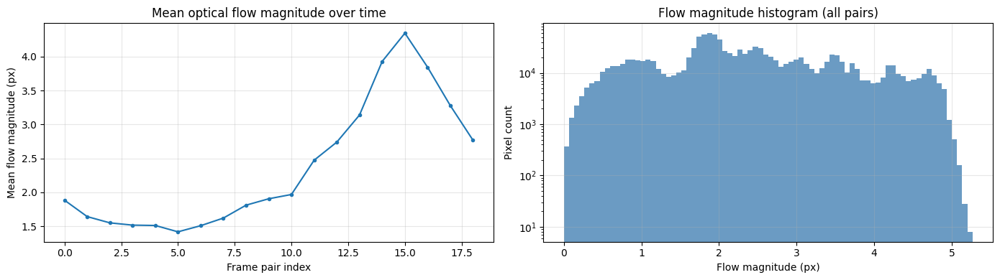

In [10]:
# ── 4.2  Flow magnitude statistics ─────────────────────────────────────────────

magnitudes = [np.sqrt(f[..., 0]**2 + f[..., 1]**2).mean() for f in forward_flows]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Mean magnitude per frame pair
axes[0].plot(magnitudes, marker="o", markersize=3)
axes[0].set_xlabel("Frame pair index")
axes[0].set_ylabel("Mean flow magnitude (px)")
axes[0].set_title("Mean optical flow magnitude over time")
axes[0].grid(True, alpha=0.3)

# Histogram of all flow magnitudes (sampled)
all_mags = np.concatenate([np.sqrt(f[..., 0]**2 + f[..., 1]**2).ravel()
                           for f in forward_flows])
axes[1].hist(all_mags, bins=80, color="steelblue", edgecolor="none", alpha=0.8)
axes[1].set_xlabel("Flow magnitude (px)")
axes[1].set_ylabel("Pixel count")
axes[1].set_title("Flow magnitude histogram (all pairs)")
axes[1].set_yscale("log")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5 — Long-Term Motion Integration

To propagate an edit from a reference frame to an arbitrary frame $t$, we need
two kinds of cumulative displacement field:

### Forward cumulative flow $\Phi_{0 \to t}$

Maps each pixel in frame 0 to its corresponding position in frame $t$:

$$
\Phi_{0 \to t}(x) = \sum_{k=0}^{t-1} F_{k \to k+1}\!\bigl(\Phi_{0 \to k}(x)\bigr)
$$

This is useful for **visualisation** (tracking where frame-0 pixels end up).

### Backward cumulative flow $\Phi_{t \to 0}$

Maps each pixel in frame $t$ **back** to its origin in frame 0.  This is what we
actually need for **edit propagation**: for every destination pixel $(x, y)$ in
frame $t$, we look up the edit residual $\Delta$ at the corresponding source
position in frame 0.

$$
\Phi_{t \to 0} = \Phi_{(t-1) \to 0} \circ F_{t \to t-1}
$$

### Drift & error accumulation

Each pairwise flow estimate has a small error $\epsilon$.  After chaining $T$ fields
the error grows roughly as $O(\sqrt{T})$ (random-walk regime) or even $O(T)$ if there
is systematic bias.  This is the fundamental challenge of **long-term motion integration**.

In [11]:
# ── 5.1  Forward cumulative displacement (for visualisation & occlusion) ──────

def build_forward_cumulative(forward_flows: List[np.ndarray]) -> List[np.ndarray]:
    """Compute forward cumulative displacement Φ_{0→t}.

    Returns
    -------
    list[np.ndarray]
        ``cumulative[t]``: (H, W, 2) displacement from frame 0 to frame t.
    """
    H, W = forward_flows[0].shape[:2]
    gx, gy = np.meshgrid(
        np.arange(W, dtype=np.float32),
        np.arange(H, dtype=np.float32),
    )
    identity = np.zeros((H, W, 2), dtype=np.float32)
    cumulative = [identity]

    for fwd in tqdm(forward_flows, desc="Integrating forward flow"):
        prev = cumulative[-1]
        abs_x = gx + prev[..., 0]
        abs_y = gy + prev[..., 1]
        inc_u = cv2.remap(fwd[..., 0], abs_x, abs_y,
                          cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
        inc_v = cv2.remap(fwd[..., 1], abs_x, abs_y,
                          cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
        new = prev.copy()
        new[..., 0] += inc_u
        new[..., 1] += inc_v
        cumulative.append(new)

    print(f"Forward: {len(cumulative)} cumulative displacement fields")
    return cumulative

cumulative_flows = build_forward_cumulative(forward_flows)

Integrating forward flow:   0%|          | 0/19 [00:00<?, ?it/s]

Forward: 20 cumulative displacement fields


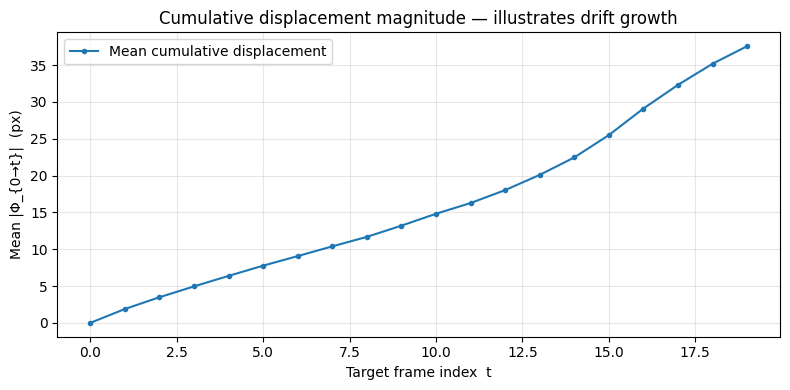

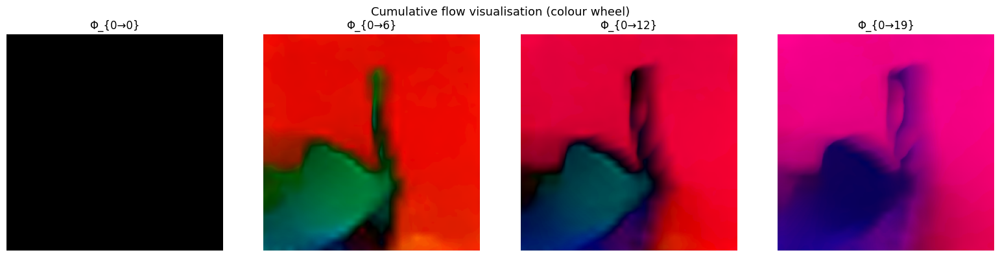

In [12]:
# ── 5.2  Visualise cumulative displacement growth ─────────────────────────────

cum_mags = [np.sqrt(c[..., 0]**2 + c[..., 1]**2).mean() for c in cumulative_flows]

plt.figure(figsize=(8, 4))
plt.plot(cum_mags, marker="o", markersize=3, label="Mean cumulative displacement")
plt.xlabel("Target frame index  t")
plt.ylabel("Mean |Φ_{0→t}|  (px)")
plt.title("Cumulative displacement magnitude — illustrates drift growth")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Show a few cumulative flow fields as colour maps
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
sample_idx = np.linspace(0, len(cumulative_flows) - 1, 4, dtype=int)
for ax, idx in zip(axes, sample_idx):
    ax.imshow(flow_to_color(cumulative_flows[idx]))
    ax.set_title(f"Φ_{{0→{idx}}}")
    ax.axis("off")
fig.suptitle("Cumulative flow visualisation (colour wheel)", fontsize=13)
plt.tight_layout()
plt.show()

## 6 — Editing Scenario: Black Swan → White Swan

We create an **edit on the reference frame** (frame 0) that turns the **black swan
into a white swan**.  The edit is represented as a residual:

$$
\Delta = I_0^{\text{edited}} - I_0^{\text{original}}
$$

To isolate the swan we use the **DAVIS ground-truth annotation mask** (included in
the dataset under `Annotations/480p/blackswan/`).  If the annotation is not
available, we fall back to a simple **luminance threshold** that captures the dark
swan body against the lighter background.

Inside the masked region we push every pixel toward white by blending:

$$
I_0^{\text{edited}}(x) = \alpha \cdot (255, 255, 255) + (1 - \alpha) \cdot I_0(x), \quad x \in \text{swan mask}
$$

with $\alpha = 0.85$, giving a convincing white-swan appearance while preserving
some texture detail.

✓ Loaded DAVIS annotation mask from DAVIS/DAVIS/Annotations/480p/blackswan/00000.png
Swan mask covers 6604 / 65536 pixels (10.1% of frame)


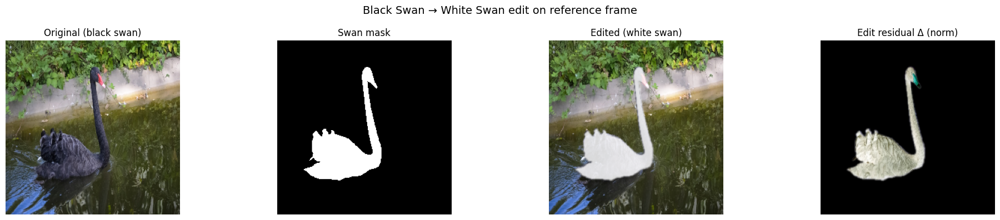

Edit residual — min: 0.0, max: 214.0, non-zero pixels: 8002


In [13]:
# ── 6.1  Create "black swan → white swan" edit on the reference frame ─────────

ref_frame = frames[0].copy()
edited_frame = ref_frame.copy()
H, W = ref_frame.shape[:2]

# ── Step A: Obtain a binary mask of the swan ──────────────────────────────────
# Try DAVIS ground-truth annotation first, then fall back to luminance threshold.

swan_mask = None

# Candidate paths where the annotation may live (DAVIS-2016 & 2017 layouts)
annotation_candidates = [
    Path("DAVIS") / "Annotations" / "480p" / DAVIS_SEQ / "00000.png",
    Path("DAVIS") / "DAVIS" / "Annotations" / "480p" / DAVIS_SEQ / "00000.png",
    Path("DAVIS") / "Annotations_unsupervised" / "480p" / DAVIS_SEQ / "00000.png",
]

for ann_path in annotation_candidates:
    if ann_path.exists():
        ann = cv2.imread(str(ann_path), cv2.IMREAD_GRAYSCALE)
        ann = cv2.resize(ann, (W, H), interpolation=cv2.INTER_NEAREST)
        swan_mask = (ann > 0).astype(np.float32)      # foreground = swan
        print(f"✓ Loaded DAVIS annotation mask from {ann_path}")
        break

if swan_mask is None:
    # Fallback: threshold on luminance — the black swan body is the darkest region
    gray = cv2.cvtColor(ref_frame, cv2.COLOR_RGB2GRAY)
    # The swan is very dark; use Otsu to find a good threshold
    _, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    # Clean up with morphological operations
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel, iterations=2)
    binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=1)
    swan_mask = (binary > 0).astype(np.float32)
    print("⚠  DAVIS annotation not found — using luminance-threshold fallback mask")

# Optional: soften the mask edges slightly to avoid harsh boundaries
swan_mask_soft = cv2.GaussianBlur(swan_mask, (5, 5), 1.0)

print(f"Swan mask covers {swan_mask.sum():.0f} / {H*W} pixels "
      f"({swan_mask.mean()*100:.1f}% of frame)")

# ── Step B: Apply the "whiten" edit ───────────────────────────────────────────
# Blend toward pure white inside the mask:  edited = α·white + (1-α)·original
alpha = 0.85
white = np.full_like(ref_frame, 255, dtype=np.float32)
edited_float = ref_frame.astype(np.float32)

for c in range(3):
    edited_float[..., c] = (
        swan_mask_soft * (alpha * white[..., c] + (1 - alpha) * edited_float[..., c])
        + (1 - swan_mask_soft) * edited_float[..., c]
    )

edited_frame = np.clip(edited_float, 0, 255).astype(np.uint8)

# Compute edit residual  Δ = edited − original  (float32, signed)
delta = edited_frame.astype(np.float32) - ref_frame.astype(np.float32)

# ── Visualise ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].imshow(ref_frame);          axes[0].set_title("Original (black swan)"); axes[0].axis("off")
axes[1].imshow(swan_mask, cmap="gray"); axes[1].set_title("Swan mask");          axes[1].axis("off")
axes[2].imshow(edited_frame);       axes[2].set_title("Edited (white swan)");    axes[2].axis("off")
# Normalise delta for display
d_vis = (delta - delta.min()) / (delta.max() - delta.min() + 1e-8)
axes[3].imshow(d_vis);              axes[3].set_title("Edit residual Δ (norm)"); axes[3].axis("off")
fig.suptitle("Black Swan → White Swan edit on reference frame", fontsize=14)
plt.tight_layout()
plt.show()

print(f"Edit residual — min: {delta.min():.1f}, max: {delta.max():.1f}, "
      f"non-zero pixels: {(np.abs(delta).sum(axis=-1) > 0).sum()}")


## 7 — Edit Propagation Using Motion Fields

To propagate the edit from frame 0 to frame $t$, we use the **backward coordinate
map** that tells us, for every pixel $(x, y)$ in frame $t$, the corresponding
position $(x_0, y_0)$ in frame 0:

$$
I_t^{\text{edited}}(x, y) = I_t(x, y) + \Delta\!\bigl(\text{map}_x^t(x,y),\; \text{map}_y^t(x,y)\bigr)
$$

The map is computed by `cv2.remap`, which does **bilinear interpolation** in
frame-0 coordinates — this is a standard backward warp.

In [14]:
# ── 7.1  Edit propagation via direct backward-flow chaining ───────────────────
#
# For each pixel (x, y) in target frame t, we trace it back to frame 0 by
# iteratively applying the pairwise backward flows:
#
#   frame t  ──[bflow t-1]──▶  frame t-1  ──[bflow t-2]──▶  …  ──[bflow 0]──▶  frame 0
#
# Then we sample the edit residual Δ at the resulting frame-0 position.
#
# This is O(T²) but trivially correct — no map composition, no sign issues.

def propagate_edit_direct(
    delta: np.ndarray,
    backward_flows: List[np.ndarray],
    frames: List[np.ndarray],
    occlusion_masks: Optional[List[np.ndarray]] = None,
    debug: bool = True,
) -> List[np.ndarray]:
    """Propagate edit residual to every frame by chaining backward flows.

    Parameters
    ----------
    delta : np.ndarray
        (H, W, 3) float32 edit residual in frame-0 coordinates.
    backward_flows : list[np.ndarray]
        ``backward_flows[k]``: pairwise flow from frame k+1 → frame k.
        Shape (H, W, 2), channels = (u_horiz, v_vert).
        ``compute_flow(frames[k+1], frames[k])`` returns displacements such that
        pixel (x, y) in frame k+1 corresponds to (x+u, y+v) in frame k.
    frames : list[np.ndarray]
        Original video frames (uint8 RGB).
    occlusion_masks : list[np.ndarray] | None
        Per-frame visibility masks; 1=visible, 0=occluded.
    debug : bool
        Print diagnostic info.

    Returns
    -------
    list[np.ndarray]
        Edited frames (uint8 RGB).
    """
    H, W = frames[0].shape[:2]
    gx, gy = np.meshgrid(
        np.arange(W, dtype=np.float32),
        np.arange(H, dtype=np.float32),
    )

    edited_frames: List[np.ndarray] = []

    for t in tqdm(range(len(frames)), desc="Propagating edit"):
        # ── Trace pixel (x,y) in frame t back to frame 0 ─────────────────
        px = gx.copy()   # current x-positions (start in frame-t coords)
        py = gy.copy()   # current y-positions

        # Walk backward:  frame t → t-1 → … → 0
        for k in range(t - 1, -1, -1):
            # backward_flows[k] lives in frame-(k+1) coordinate system.
            # Our current (px, py) are positions in frame-(k+1). ✓
            bflow_u = cv2.remap(
                backward_flows[k][..., 0], px, py,
                cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE,
            )
            bflow_v = cv2.remap(
                backward_flows[k][..., 1], px, py,
                cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE,
            )
            px = px + bflow_u   # now in frame-k coordinate system
            py = py + bflow_v

        # px, py are now frame-0 coordinates for each frame-t pixel ────────
        warped_delta = cv2.remap(
            delta, px, py,
            cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0,
        )

        if occlusion_masks is not None:
            warped_delta = warped_delta * occlusion_masks[t][..., np.newaxis]

        result = np.clip(
            frames[t].astype(np.float32) + warped_delta, 0, 255
        ).astype(np.uint8)
        edited_frames.append(result)

        # ── Debug diagnostics ─────────────────────────────────────────────
        if debug and t in (0, 1, len(frames) // 2, len(frames) - 1):
            disp = np.sqrt((px - gx) ** 2 + (py - gy) ** 2)
            wd_nnz = (np.abs(warped_delta).sum(axis=-1) > 0.5).sum()
            print(
                f"  t={t:>2d}:  displacement mean={disp.mean():.2f} max={disp.max():.2f} px  |  "
                f"warped_delta nonzero={wd_nnz}  range=[{warped_delta.min():.1f}, {warped_delta.max():.1f}]"
            )

    return edited_frames

Delta stats before propagation:
  shape=(256, 256, 3), dtype=float32
  min=0.0, max=214.0
  nonzero pixels: 8002
Number of backward flows: 19
  bflow[0] magnitude:  mean=1.85  max=3.39
  bflow[9] magnitude:  mean=1.87  max=3.44
  bflow[18] magnitude:  mean=2.78  max=4.25



Propagating edit:   0%|          | 0/20 [00:00<?, ?it/s]

  t= 0:  displacement mean=0.00 max=0.00 px  |  warped_delta nonzero=8002  range=[0.0, 214.0]
  t= 1:  displacement mean=1.85 max=3.39 px  |  warped_delta nonzero=8193  range=[0.0, 212.0]
  t=10:  displacement mean=14.98 max=23.52 px  |  warped_delta nonzero=9837  range=[0.0, 211.9]
  t=19:  displacement mean=40.28 max=59.70 px  |  warped_delta nonzero=11550  range=[0.0, 211.9]

✓ Generated 20 edited frames.


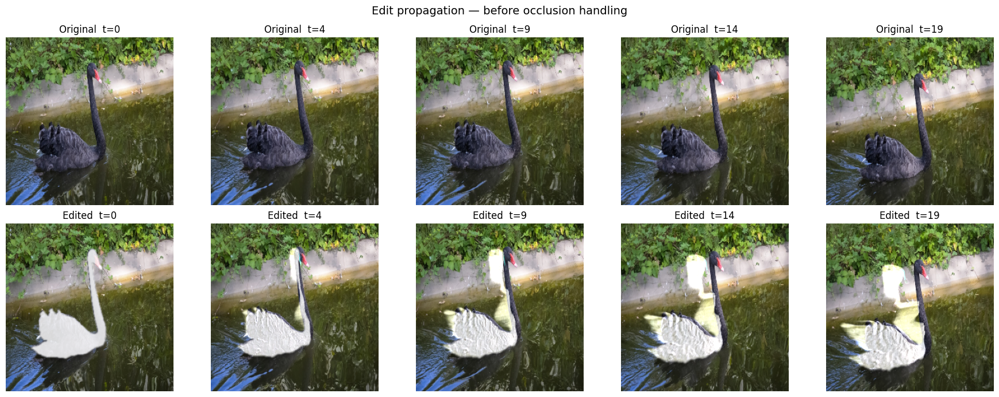

In [15]:
# ── 7.2  Propagate edit to all frames (no occlusion handling yet) ──────────────

print("Delta stats before propagation:")
print(f"  shape={delta.shape}, dtype={delta.dtype}")
print(f"  min={delta.min():.1f}, max={delta.max():.1f}")
print(f"  nonzero pixels: {(np.abs(delta).sum(axis=-1) > 0.5).sum()}")
print(f"Number of backward flows: {len(backward_flows)}")
for i in [0, len(backward_flows)//2, len(backward_flows)-1]:
    bf = backward_flows[i]
    mag = np.sqrt(bf[...,0]**2 + bf[...,1]**2)
    print(f"  bflow[{i}] magnitude:  mean={mag.mean():.2f}  max={mag.max():.2f}")
print()

edited_frames = propagate_edit_direct(
    delta, backward_flows, frames, occlusion_masks=None, debug=True,
)

print(f"\n✓ Generated {len(edited_frames)} edited frames.")

# Quick peek
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
sample_idx = np.linspace(0, len(frames) - 1, 5, dtype=int)
for col, idx in enumerate(sample_idx):
    axes[0, col].imshow(frames[idx])
    axes[0, col].set_title(f"Original  t={idx}")
    axes[0, col].axis("off")
    axes[1, col].imshow(edited_frames[idx])
    axes[1, col].set_title(f"Edited  t={idx}")
    axes[1, col].axis("off")
fig.suptitle("Edit propagation — before occlusion handling", fontsize=14)
plt.tight_layout()
plt.show()

## 8 — Occlusion Handling (Basic)

Pixels that become **occluded** (hidden behind another object) between frame 0 and
frame $t$ should **not** receive the propagated edit — the edit would land on a
wrong surface.

We implement two simple heuristics:

### 8a. Forward-backward consistency check

If the forward flow $F_{t \to t+1}$ and the backward flow $F_{t+1 \to t}$
are consistent, then composing them should yield near-zero displacement:

$$
\|F_{t \to t+1}(x) + F_{t+1 \to t}(x + F_{t \to t+1}(x))\| < \tau
$$

Pixels violating this are likely occluded or at motion boundaries.

### 8b. Magnitude threshold

Extremely large cumulative displacements often correspond to pixels that have
drifted out of the valid region.

**Limitation:** These are coarse heuristics.  Robust occlusion reasoning
typically requires multi-frame reasoning or learned occlusion predictors.

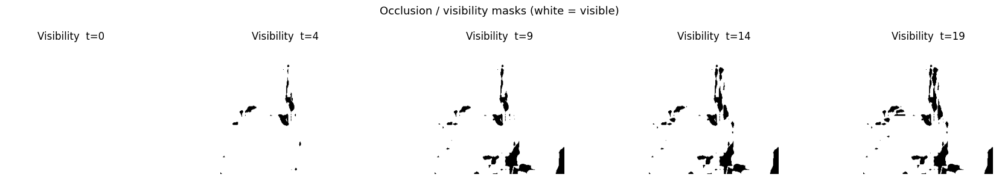

In [16]:
# ── 8.1  Forward-backward consistency check ────────────────────────────────────

def fb_consistency_mask(
    fwd_flow: np.ndarray,
    bwd_flow: np.ndarray,
    threshold: float = 1.5,
) -> np.ndarray:
    """Compute a binary visibility mask via forward-backward consistency.

    For each pixel x in frame t,  warp backward flow to x using the forward
    flow and check if  ||F_fwd(x) + F_bwd(x + F_fwd(x))|| < threshold.

    Parameters
    ----------
    fwd_flow : np.ndarray   (H, W, 2)  — frame t → t+1
    bwd_flow : np.ndarray   (H, W, 2)  — frame t+1 → t
    threshold : float        consistency threshold in pixels.

    Returns
    -------
    np.ndarray
        Binary mask (H, W), float32.  1 = consistent (visible), 0 = occluded.
    """
    H, W = fwd_flow.shape[:2]
    x = np.arange(W, dtype=np.float32)
    y = np.arange(H, dtype=np.float32)
    gx, gy = np.meshgrid(x, y)

    # Displaced positions in frame t+1
    map_x = gx + fwd_flow[..., 0]
    map_y = gy + fwd_flow[..., 1]

    # Sample backward flow at those positions
    bwd_u = cv2.remap(bwd_flow[..., 0], map_x, map_y,
                       cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    bwd_v = cv2.remap(bwd_flow[..., 1], map_x, map_y,
                       cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)

    # Residual should be near zero for consistent pixels
    residual = np.sqrt((fwd_flow[..., 0] + bwd_u) ** 2 +
                       (fwd_flow[..., 1] + bwd_v) ** 2)

    return (residual < threshold).astype(np.float32)


# ── 8.2  Cumulative occlusion masks ──────────────────────────────────────────

def compute_occlusion_masks(
    forward_flows: List[np.ndarray],
    backward_flows: List[np.ndarray],
    cumulative_flows: List[np.ndarray],
    fb_thresh: float = 1.5,
    mag_thresh: float = 150.0,
) -> List[np.ndarray]:
    """Compute per-frame occlusion masks combining FB-check and magnitude clamp.

    Returns
    -------
    list[np.ndarray]
        ``masks[t]``: (H, W) float32, 1 = visible, 0 = occluded.
    """
    H, W = forward_flows[0].shape[:2]
    masks = [np.ones((H, W), dtype=np.float32)]  # Frame 0 — fully visible

    running_vis = np.ones((H, W), dtype=np.float32)

    for i in range(len(forward_flows)):
        # Per-pair FB check
        fb = fb_consistency_mask(forward_flows[i], backward_flows[i], fb_thresh)
        running_vis = running_vis * fb  # Accumulate — once occluded, stays occluded

        # Magnitude threshold on cumulative displacement
        cum_mag = np.sqrt(cumulative_flows[i + 1][..., 0] ** 2 +
                          cumulative_flows[i + 1][..., 1] ** 2)
        mag_ok = (cum_mag < mag_thresh).astype(np.float32)

        masks.append(running_vis * mag_ok)

    return masks


occlusion_masks = compute_occlusion_masks(
    forward_flows, backward_flows, cumulative_flows
)

# Visualise a few masks
fig, axes = plt.subplots(1, 5, figsize=(18, 3))
sample_idx = np.linspace(0, len(occlusion_masks) - 1, 5, dtype=int)
for ax, idx in zip(axes, sample_idx):
    ax.imshow(occlusion_masks[idx], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Visibility  t={idx}")
    ax.axis("off")
fig.suptitle("Occlusion / visibility masks (white = visible)", fontsize=13)
plt.tight_layout()
plt.show()

Propagating edit:   0%|          | 0/20 [00:00<?, ?it/s]

  t= 0:  displacement mean=0.00 max=0.00 px  |  warped_delta nonzero=8002  range=[0.0, 214.0]
  t= 1:  displacement mean=1.85 max=3.39 px  |  warped_delta nonzero=8112  range=[0.0, 212.0]
  t=10:  displacement mean=14.98 max=23.52 px  |  warped_delta nonzero=8965  range=[0.0, 211.9]
  t=19:  displacement mean=40.28 max=59.70 px  |  warped_delta nonzero=10917  range=[0.0, 211.9]


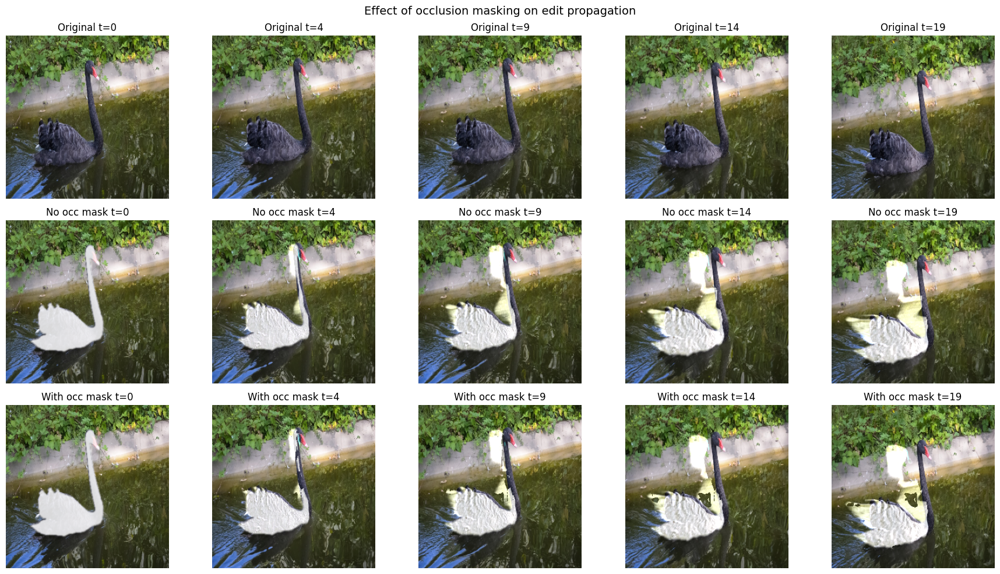

In [17]:
# ── 8.3  Re-propagate with occlusion-aware masking ────────────────────────────

edited_frames_occ = propagate_edit_direct(
    delta, backward_flows, frames,
    occlusion_masks=occlusion_masks,
    debug=True,
)

# Compare with / without occlusion handling
fig, axes = plt.subplots(3, 5, figsize=(18, 10))
sample_idx = np.linspace(0, len(frames) - 1, 5, dtype=int)
for col, idx in enumerate(sample_idx):
    axes[0, col].imshow(frames[idx])
    axes[0, col].set_title(f"Original t={idx}")
    axes[0, col].axis("off")

    axes[1, col].imshow(edited_frames[idx])
    axes[1, col].set_title(f"No occ mask t={idx}")
    axes[1, col].axis("off")

    axes[2, col].imshow(edited_frames_occ[idx])
    axes[2, col].set_title(f"With occ mask t={idx}")
    axes[2, col].axis("off")

fig.suptitle("Effect of occlusion masking on edit propagation", fontsize=14)
plt.tight_layout()
plt.show()

## 9 — Visualization & Output Video

We display the full result and save the edited sequence as a video file.

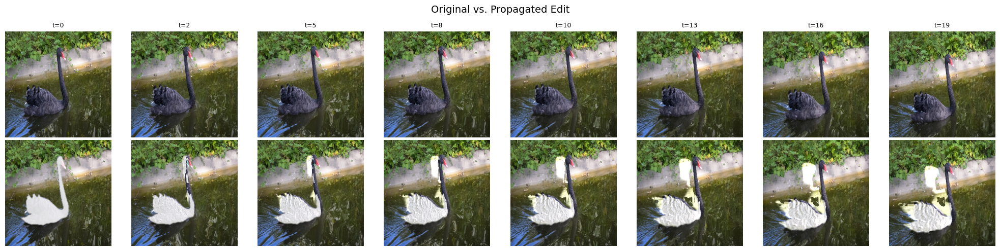

In [18]:
# ── 9.1  Side-by-side strip: original vs. edited ──────────────────────────────

def make_comparison_strip(
    originals: List[np.ndarray],
    edited: List[np.ndarray],
    n_cols: int = 8,
) -> None:
    """Show a side-by-side comparison strip (original top, edited bottom)."""
    indices = np.linspace(0, len(originals) - 1, n_cols, dtype=int)
    fig, axes = plt.subplots(2, n_cols, figsize=(2.5 * n_cols, 5))
    for col, idx in enumerate(indices):
        axes[0, col].imshow(originals[idx])
        axes[0, col].set_title(f"t={idx}", fontsize=9)
        axes[0, col].axis("off")
        axes[1, col].imshow(edited[idx])
        axes[1, col].axis("off")
    axes[0, 0].set_ylabel("Original", fontsize=11)
    axes[1, 0].set_ylabel("Edited", fontsize=11)
    fig.suptitle("Original vs. Propagated Edit", fontsize=14)
    plt.tight_layout()
    plt.show()

make_comparison_strip(frames, edited_frames_occ)

In [19]:
# ── 9.2  Save output video ─────────────────────────────────────────────────────

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

def save_video(
    frames_list: List[np.ndarray],
    path: str,
    fps: int = 10,
) -> None:
    """Save a list of uint8 RGB frames as a video file.

    Tries OpenCV's VideoWriter first (no extra dependencies), then falls
    back to imageio+ffmpeg, and finally to an animated GIF.
    """
    H, W = frames_list[0].shape[:2]
    success = False

    # --- Attempt 1: OpenCV VideoWriter (mp4v codec) -----------------------
    try:
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        out = cv2.VideoWriter(path, fourcc, fps, (W, H))
        if out.isOpened():
            for f in frames_list:
                out.write(cv2.cvtColor(f, cv2.COLOR_RGB2BGR))
            out.release()
            success = True
    except Exception:
        pass

    # --- Attempt 2: imageio + ffmpeg --------------------------------------
    if not success:
        try:
            writer = imageio.get_writer(path, fps=fps, codec="libx264", quality=8)
            for f in frames_list:
                writer.append_data(f)
            writer.close()
            success = True
        except Exception:
            pass

    # --- Attempt 3: animated GIF fallback ---------------------------------
    if not success:
        gif_path = path.rsplit(".", 1)[0] + ".gif"
        imageio.mimsave(gif_path, frames_list, fps=fps)
        print(f"✓ Saved GIF → {gif_path}  ({len(frames_list)} frames, {fps} fps)")
        return

    print(f"✓ Saved video → {path}  ({len(frames_list)} frames, {fps} fps)")

# Save original, edited (naive), edited (occ-aware)
save_video(frames,            str(OUTPUT_DIR / "original.mp4"))
save_video(edited_frames,     str(OUTPUT_DIR / "edited_naive.mp4"))
save_video(edited_frames_occ, str(OUTPUT_DIR / "edited_occ_aware.mp4"))

# Also save a side-by-side video
sidebyside = [np.concatenate([o, e], axis=1)
              for o, e in zip(frames, edited_frames_occ)]
save_video(sidebyside, str(OUTPUT_DIR / "comparison_sidebyside.mp4"))

✓ Saved video → output/original.mp4  (20 frames, 10 fps)
✓ Saved video → output/edited_naive.mp4  (20 frames, 10 fps)
✓ Saved video → output/edited_occ_aware.mp4  (20 frames, 10 fps)
✓ Saved video → output/comparison_sidebyside.mp4  (20 frames, 10 fps)


In [20]:
# ── 9.3  Interactive frame browser (slider) ────────────────────────────────────
# Works in Jupyter / Colab; falls back to a static display otherwise.

try:
    from ipywidgets import interact, IntSlider

    @interact(t=IntSlider(min=0, max=len(frames)-1, step=1, value=0,
                          description="Frame t"))
    def browse_frames(t: int) -> None:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        axes[0].imshow(frames[t]);            axes[0].set_title("Original"); axes[0].axis("off")
        axes[1].imshow(edited_frames_occ[t]); axes[1].set_title("Edited");   axes[1].axis("off")
        diff = np.abs(frames[t].astype(np.float32) - edited_frames_occ[t].astype(np.float32))
        axes[2].imshow(diff.astype(np.uint8)); axes[2].set_title("| Diff |"); axes[2].axis("off")
        plt.tight_layout()
        plt.show()

except ImportError:
    print("ipywidgets not available — skipping interactive slider.")

interactive(children=(IntSlider(value=0, description='Frame t', max=19), Output()), _dom_classes=('widget-inte…

## 10 — Evaluation

We assess: **temporal consistency** (smoothness between consecutive edited frames),
**edit accuracy** (how well the edit tracks the object), and identify **failure cases**.

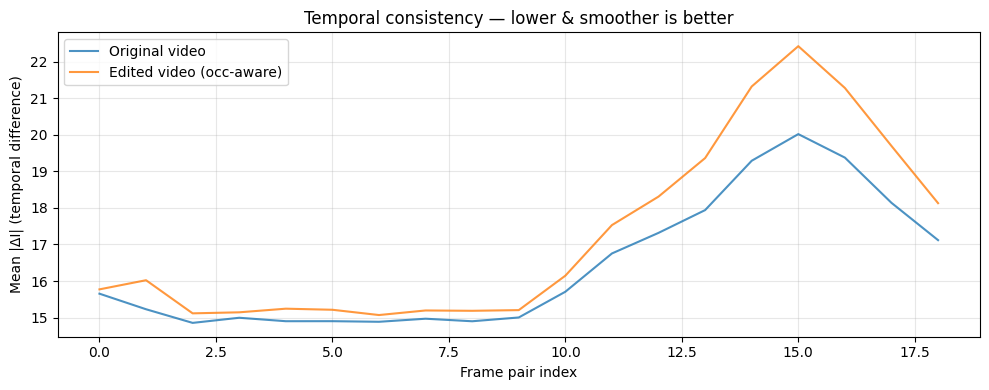

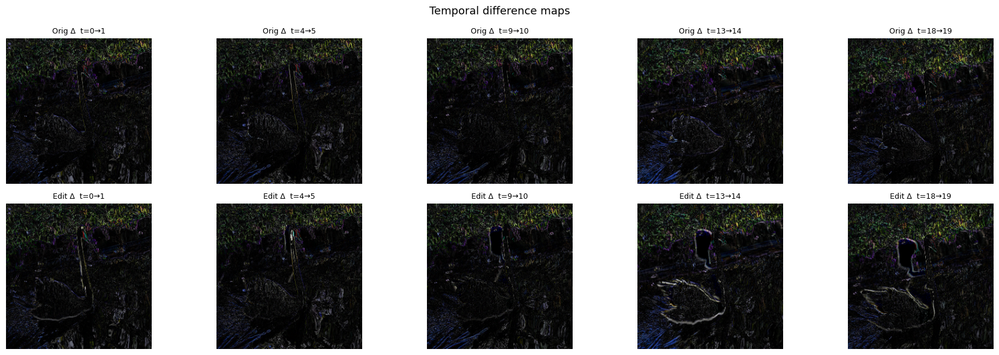

In [21]:
# ── 10.1  Temporal difference maps ─────────────────────────────────────────────
# Measure how much the edited video changes between consecutive frames.
# A temporally consistent result should change smoothly.

def temporal_difference(
    frames_list: List[np.ndarray],
) -> Tuple[List[np.ndarray], List[float]]:
    """Compute per-pixel absolute difference between consecutive frames.

    Returns
    -------
    diff_maps : list[np.ndarray]
        Absolute difference images (uint8).
    scores : list[float]
        Mean absolute difference per pair.
    """
    diff_maps = []
    scores = []
    for i in range(len(frames_list) - 1):
        d = np.abs(frames_list[i + 1].astype(np.float32) -
                   frames_list[i].astype(np.float32))
        diff_maps.append(d.astype(np.uint8))
        scores.append(d.mean())
    return diff_maps, scores


orig_diffs, orig_scores = temporal_difference(frames)
edit_diffs, edit_scores = temporal_difference(edited_frames_occ)

plt.figure(figsize=(10, 4))
plt.plot(orig_scores, label="Original video", alpha=0.8)
plt.plot(edit_scores, label="Edited video (occ-aware)", alpha=0.8)
plt.xlabel("Frame pair index")
plt.ylabel("Mean |ΔI| (temporal difference)")
plt.title("Temporal consistency — lower & smoother is better")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Show temporal diff maps at a few time steps
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
sample_idx = np.linspace(0, len(edit_diffs) - 1, 5, dtype=int)
for col, idx in enumerate(sample_idx):
    axes[0, col].imshow(orig_diffs[idx])
    axes[0, col].set_title(f"Orig Δ  t={idx}→{idx+1}", fontsize=9)
    axes[0, col].axis("off")
    axes[1, col].imshow(edit_diffs[idx])
    axes[1, col].set_title(f"Edit Δ  t={idx}→{idx+1}", fontsize=9)
    axes[1, col].axis("off")
fig.suptitle("Temporal difference maps", fontsize=13)
plt.tight_layout()
plt.show()

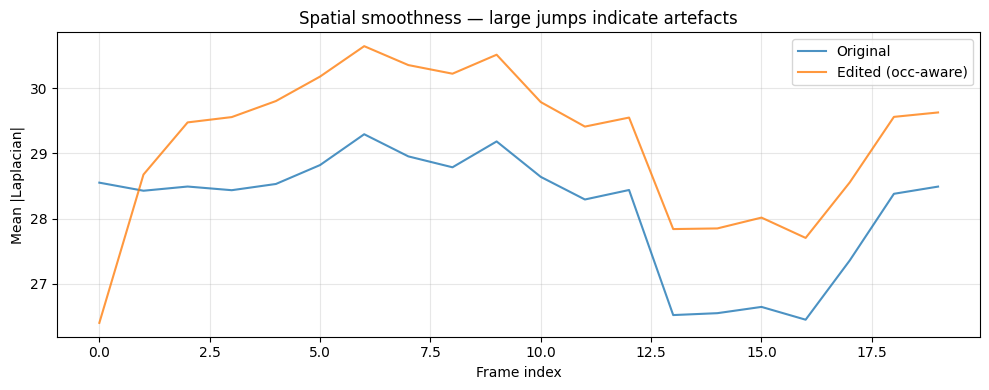

In [22]:
# ── 10.2  Smoothness measure (Laplacian energy) ───────────────────────────────
# We compute the spatial Laplacian energy of the edit delta warped to each frame.
# High-frequency artefacts (tears, ghosting) increase this energy.

def laplacian_energy(image: np.ndarray) -> float:
    """Mean absolute Laplacian — proxy for spatial smoothness of an image."""
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY) if image.ndim == 3 else image
    lap = cv2.Laplacian(gray, cv2.CV_64F)
    return float(np.abs(lap).mean())


smooth_orig = [laplacian_energy(f) for f in frames]
smooth_edit = [laplacian_energy(f) for f in edited_frames_occ]

plt.figure(figsize=(10, 4))
plt.plot(smooth_orig, label="Original", alpha=0.8)
plt.plot(smooth_edit, label="Edited (occ-aware)", alpha=0.8)
plt.xlabel("Frame index")
plt.ylabel("Mean |Laplacian|")
plt.title("Spatial smoothness — large jumps indicate artefacts")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

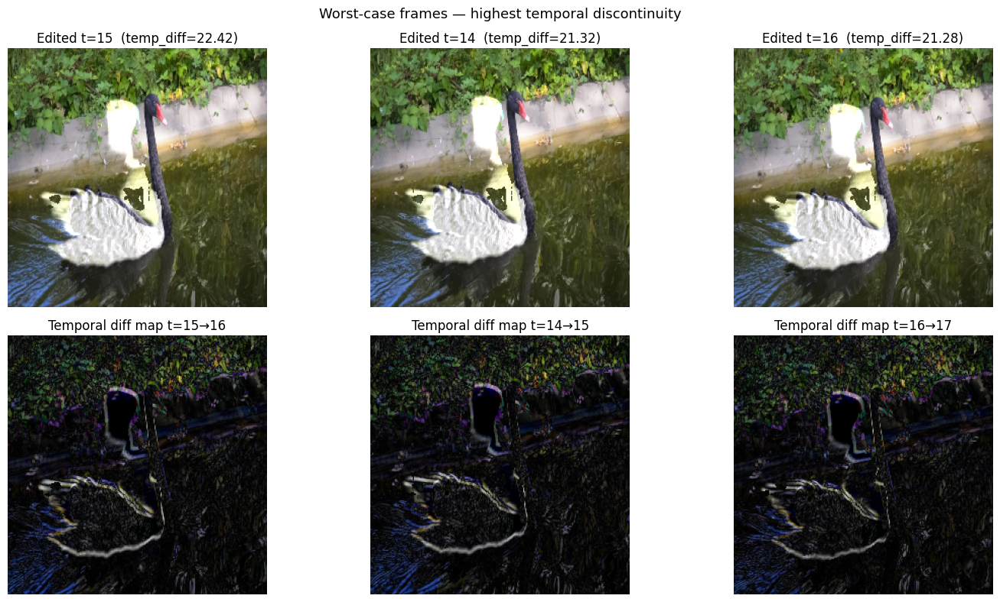

Artefact explanation:
  • Ghost trails appear when the flow field drifts, causing the warped edit to
    land on the wrong surface.
  • Sharp edges in the temporal-diff maps indicate motion boundary errors where
    foreground/background flows are mixed.
  • At late frames the cumulative displacement error compounds (drift), causing
    the edit to slide away from the intended region.


In [23]:
# ── 10.3  Failure-case analysis ─────────────────────────────────────────────────
# Identify frames where the edit looks worst — large temporal jump or high Laplacian.

temporal_jump = np.array(edit_scores)
worst_frames = np.argsort(temporal_jump)[-3:][::-1]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, idx in enumerate(worst_frames):
    axes[0, col].imshow(edited_frames_occ[idx])
    axes[0, col].set_title(f"Edited t={idx}  (temp_diff={temporal_jump[idx]:.2f})")
    axes[0, col].axis("off")
    axes[1, col].imshow(edit_diffs[idx])
    axes[1, col].set_title(f"Temporal diff map t={idx}→{idx+1}")
    axes[1, col].axis("off")
fig.suptitle("Worst-case frames — highest temporal discontinuity", fontsize=13)
plt.tight_layout()
plt.show()

print("Artefact explanation:")
print("  • Ghost trails appear when the flow field drifts, causing the warped edit to")
print("    land on the wrong surface.")
print("  • Sharp edges in the temporal-diff maps indicate motion boundary errors where")
print("    foreground/background flows are mixed.")
print("  • At late frames the cumulative displacement error compounds (drift), causing")
print("    the edit to slide away from the intended region.")

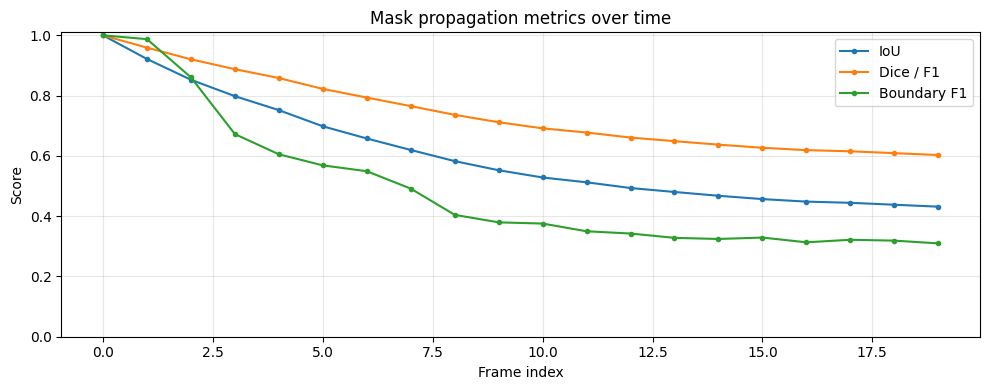

Mask metrics (mean / median / std):
  IoU        0.6068 / 0.5404 / 0.1707
  Dice/F1    0.7422 / 0.7015 / 0.1235
  BoundaryF1 0.4916 / 0.3775 / 0.2209


In [24]:
# -- 10.35  Mask metrics vs DAVIS GT (IoU / Dice / Boundary F1) --

def propagate_binary_mask_direct(ref_mask: np.ndarray, backward_flows: List[np.ndarray], num_frames: int) -> List[np.ndarray]:
    H, W = ref_mask.shape
    gx, gy = np.meshgrid(np.arange(W, dtype=np.float32), np.arange(H, dtype=np.float32))
    ref_u8 = (ref_mask > 0.5).astype(np.uint8)
    out = []
    for t in range(num_frames):
        px = gx.copy()
        py = gy.copy()
        for k in range(t - 1, -1, -1):
            bu = cv2.remap(backward_flows[k][..., 0], px, py, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
            bv = cv2.remap(backward_flows[k][..., 1], px, py, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
            px = px + bu
            py = py + bv
        warped = cv2.remap(ref_u8, px, py, cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        out.append((warped > 0).astype(np.uint8))
    return out

def load_davis_annotation_masks(sequence: str, n_frames: int, shape_hw: Tuple[int, int]) -> List[np.ndarray]:
    H, W = shape_hw
    candidates = [
        Path("DAVIS") / "Annotations" / "480p" / sequence,
        Path("DAVIS") / "DAVIS" / "Annotations" / "480p" / sequence,
        Path("DAVIS") / "Annotations_unsupervised" / "480p" / sequence,
        Path("DAVIS") / "DAVIS" / "Annotations_unsupervised" / "480p" / sequence,
    ]
    ann_dir = next((d for d in candidates if d.exists() and d.is_dir() and any(d.iterdir())), None)
    if ann_dir is None:
        raise FileNotFoundError("DAVIS annotation folder not found.")
    ann_paths = sorted([p for p in ann_dir.iterdir() if p.suffix.lower() in {".png", ".jpg", ".jpeg"}])[:n_frames]
    masks = []
    for p in ann_paths:
        m = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
        m = cv2.resize(m, (W, H), interpolation=cv2.INTER_NEAREST)
        masks.append((m > 0).astype(np.uint8))
    return masks

def iou_score(pred: np.ndarray, gt: np.ndarray) -> float:
    pred_b = pred.astype(bool)
    gt_b = gt.astype(bool)
    inter = np.logical_and(pred_b, gt_b).sum()
    union = np.logical_or(pred_b, gt_b).sum()
    return float(inter / (union + 1e-8))

def dice_score(pred: np.ndarray, gt: np.ndarray) -> float:
    pred_b = pred.astype(bool)
    gt_b = gt.astype(bool)
    inter = np.logical_and(pred_b, gt_b).sum()
    return float((2.0 * inter) / (pred_b.sum() + gt_b.sum() + 1e-8))

def boundary_map(mask: np.ndarray) -> np.ndarray:
    m = (mask > 0).astype(np.uint8)
    eroded = cv2.erode(m, np.ones((3, 3), dtype=np.uint8), iterations=1)
    return (m - eroded > 0).astype(np.uint8)

def boundary_f1_score(pred: np.ndarray, gt: np.ndarray, tolerance_px: int = 2) -> float:
    pb = boundary_map(pred)
    gb = boundary_map(gt)
    if pb.sum() == 0 and gb.sum() == 0:
        return 1.0
    if pb.sum() == 0 or gb.sum() == 0:
        return 0.0
    k = max(1, int(tolerance_px))
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * k + 1, 2 * k + 1))
    pb_d = cv2.dilate(pb, kernel, iterations=1)
    gb_d = cv2.dilate(gb, kernel, iterations=1)
    precision = np.logical_and(pb > 0, gb_d > 0).sum() / (pb.sum() + 1e-8)
    recall = np.logical_and(gb > 0, pb_d > 0).sum() / (gb.sum() + 1e-8)
    return float((2.0 * precision * recall) / (precision + recall + 1e-8))

if "swan_mask" in globals() and swan_mask is not None:
    ref_mask_eval = (swan_mask > 0.5).astype(np.uint8)
elif "swan_mask_soft" in globals() and swan_mask_soft is not None:
    ref_mask_eval = (swan_mask_soft > 0.5).astype(np.uint8)
else:
    g0 = cv2.cvtColor(frames[0], cv2.COLOR_RGB2GRAY)
    _, b0 = cv2.threshold(g0, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    ref_mask_eval = (b0 > 0).astype(np.uint8)

prop_masks = propagate_binary_mask_direct(ref_mask_eval, backward_flows, len(frames))
gt_masks = load_davis_annotation_masks(DAVIS_SEQ, len(frames), frames[0].shape[:2])
n_eval = min(len(prop_masks), len(gt_masks))

iou_per_frame = np.array([iou_score(prop_masks[t], gt_masks[t]) for t in range(n_eval)])
dice_per_frame = np.array([dice_score(prop_masks[t], gt_masks[t]) for t in range(n_eval)])
bf_per_frame = np.array([boundary_f1_score(prop_masks[t], gt_masks[t], tolerance_px=2) for t in range(n_eval)])

plt.figure(figsize=(10, 4))
plt.plot(iou_per_frame, marker="o", markersize=3, label="IoU")
plt.plot(dice_per_frame, marker="o", markersize=3, label="Dice / F1")
plt.plot(bf_per_frame, marker="o", markersize=3, label="Boundary F1")
plt.xlabel("Frame index")
plt.ylabel("Score")
plt.ylim(0.0, 1.01)
plt.title("Mask propagation metrics over time")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Mask metrics (mean / median / std):")
print(f"  IoU        {iou_per_frame.mean():.4f} / {np.median(iou_per_frame):.4f} / {iou_per_frame.std():.4f}")
print(f"  Dice/F1    {dice_per_frame.mean():.4f} / {np.median(dice_per_frame):.4f} / {dice_per_frame.std():.4f}")
print(f"  BoundaryF1 {bf_per_frame.mean():.4f} / {np.median(bf_per_frame):.4f} / {bf_per_frame.std():.4f}")

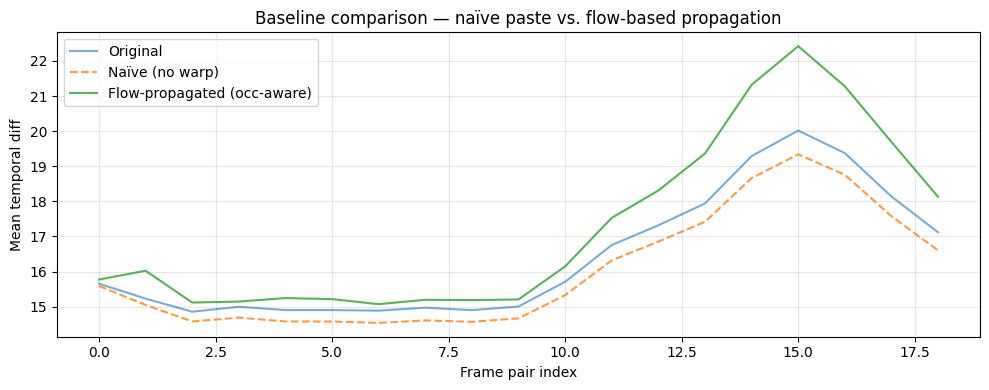

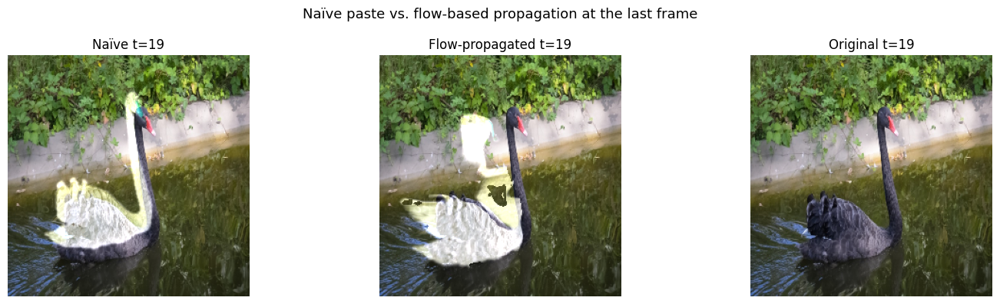

In [25]:
# ── 10.4  Bonus: Comparison with naïve warping baseline ────────────────────────
# Baseline: instead of using learned optical flow, simply copy the edit residual
# without any warping (i.e. paste it at fixed coordinates in every frame).

naive_edited: List[np.ndarray] = []
for t in range(len(frames)):
    result = np.clip(frames[t].astype(np.float32) + delta, 0, 255).astype(np.uint8)
    naive_edited.append(result)

_, naive_scores = temporal_difference(naive_edited)

plt.figure(figsize=(10, 4))
plt.plot(orig_scores, label="Original", alpha=0.6)
plt.plot(naive_scores, label="Naïve (no warp)", alpha=0.8, linestyle="--")
plt.plot(edit_scores, label="Flow-propagated (occ-aware)", alpha=0.8)
plt.xlabel("Frame pair index")
plt.ylabel("Mean temporal diff")
plt.title("Baseline comparison — naïve paste vs. flow-based propagation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Visual comparison at a late frame
t_late = len(frames) - 1
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(naive_edited[t_late]);       axes[0].set_title(f"Naïve t={t_late}");           axes[0].axis("off")
axes[1].imshow(edited_frames_occ[t_late]);  axes[1].set_title(f"Flow-propagated t={t_late}"); axes[1].axis("off")
axes[2].imshow(frames[t_late]);             axes[2].set_title(f"Original t={t_late}");         axes[2].axis("off")
fig.suptitle("Naïve paste vs. flow-based propagation at the last frame", fontsize=13)
plt.tight_layout()
plt.show()

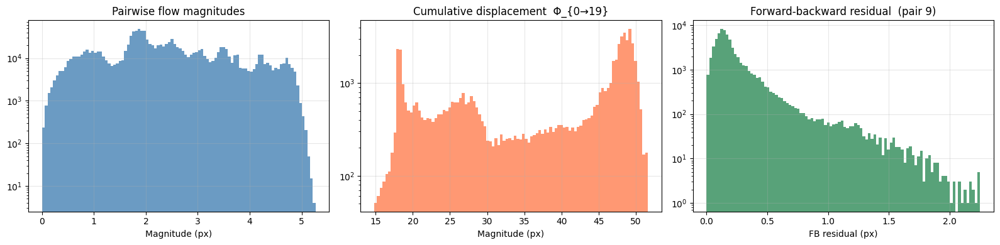

In [26]:
# ── 10.5  Bonus: Flow magnitude histogram ──────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Per-pair flow magnitudes
all_fwd_mag = np.concatenate([np.sqrt(f[...,0]**2 + f[...,1]**2).ravel()
                               for f in forward_flows])
axes[0].hist(all_fwd_mag, bins=100, color="steelblue", edgecolor="none", alpha=0.8)
axes[0].set_xlabel("Magnitude (px)")
axes[0].set_title("Pairwise flow magnitudes")
axes[0].set_yscale("log")

# Cumulative displacement magnitudes at last frame
cum_last = np.sqrt(cumulative_flows[-1][..., 0]**2 + cumulative_flows[-1][..., 1]**2)
axes[1].hist(cum_last.ravel(), bins=100, color="coral", edgecolor="none", alpha=0.8)
axes[1].set_xlabel("Magnitude (px)")
axes[1].set_title(f"Cumulative displacement  Φ_{{0→{len(frames)-1}}}")
axes[1].set_yscale("log")

# FB consistency residual at mid-sequence
mid = len(forward_flows) // 2
fb_residual = fb_consistency_mask(forward_flows[mid], backward_flows[mid], threshold=9999)
# (we used threshold=9999 to get the raw mask → but let's compute residual directly)
H, W = forward_flows[mid].shape[:2]
gx, gy = np.meshgrid(np.arange(W, dtype=np.float32), np.arange(H, dtype=np.float32))
mx = gx + forward_flows[mid][..., 0]
my = gy + forward_flows[mid][..., 1]
bu = cv2.remap(backward_flows[mid][..., 0], mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
bv = cv2.remap(backward_flows[mid][..., 1], mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
fb_res = np.sqrt((forward_flows[mid][..., 0] + bu)**2 + (forward_flows[mid][..., 1] + bv)**2)
axes[2].hist(fb_res.ravel(), bins=100, color="seagreen", edgecolor="none", alpha=0.8)
axes[2].set_xlabel("FB residual (px)")
axes[2].set_title(f"Forward-backward residual  (pair {mid})")
axes[2].set_yscale("log")

for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11 — Discussion

### Strengths of learning-based optical flow

| Advantage | Explanation |
|---|---|
| **End-to-end learning** | FlowNet / RAFT learn directly from data, avoiding hand-crafted energy terms and iterative solvers (e.g. Horn-Schunck, Lucas-Kanade). |
| **Sub-pixel accuracy** | CNN features encode texture and semantic cues, enabling precise matching even in low-contrast regions. |
| **Speed** | A single forward pass is orders of magnitude faster than classical variational methods at comparable resolution. |
| **Generalisation** | Models pretrained on synthetic data (FlyingChairs, FlyingThings3D) transfer well to real-world sequences. |

### Limitations

1. **Drift accumulation** — Each pairwise flow estimate carries error $\epsilon$.
   Chaining $T$ fields yields cumulative error $\sim O(\sqrt{T})$ (random) to $O(T)$
   (systematic).  For long sequences this causes the propagated edit to visibly slide
   away from the correct region.

2. **Occlusion** — Pixels that become occluded have *no* valid correspondence; naively
   warping through them creates ghosting.  Our forward-backward check mitigates this
   but is a coarse heuristic.

3. **Large motion / fast objects** — Standard FlowNet architectures struggle with
   displacements larger than the receptive field.  RAFT's iterative lookup partially
   addresses this, but very fast motion still produces artefacts.

4. **Motion boundaries** — Flow estimates are typically blurred at object boundaries
   because CNNs apply learned spatial smoothness.  This causes "bleeding" of the edit
   across depth discontinuities.

5. **Appearance change** — Lighting variations, deformation, and view-dependent effects
   invalidate the brightness constancy assumption implicit in optical flow.

### Possible improvements

- **Bi-directional propagation with keyframes** — propagate forward *and* backward
  from multiple edited keyframes and blend results, reducing single-direction drift.
- **Learned occlusion prediction** — train a small network to predict occlusion masks
  jointly with flow.
- **Feature-space warping** — warp in a learned feature space rather than pixel space,
  which is more robust to appearance change.
- **Test-time optimisation** — fine-tune the flow model on the specific video for
  improved accuracy (self-supervised via photometric loss).
- **Transformer-based flow** (FlowFormer, VideoFlow) — global attention captures
  long-range correspondences that convolutional models miss.

---

### References

1. Dosovitskiy et al., "FlowNet: Learning Optical Flow with Convolutional Networks", ICCV 2015.
2. Ilg et al., "FlowNet 2.0: Evolution of Optical Flow Estimation with Deep Networks", CVPR 2017.
3. Teed & Deng, "RAFT: Recurrent All-Pairs Field Transforms for Optical Flow", ECCV 2020.
4. Huang et al., "FlowFormer: A Transformer Architecture for Optical Flow", ECCV 2022.

In [27]:
# ── Final summary print ────────────────────────────────────────────────────────

print("=" * 70)
print("  Pipeline complete.")
print("=" * 70)
print(f"  Frames processed       : {len(frames)}")
print(f"  Flow model             : {flow_estimator.model_name}")
print(f"  Device                 : {DEVICE}")
print(f"  Pairwise flows         : {len(forward_flows)} forward + {len(backward_flows)} backward")
print(f"  Cumulative fields      : {len(cumulative_flows)}")
print(f"  Occlusion masks        : {len(occlusion_masks)}")
print(f"  Output videos saved to : {OUTPUT_DIR.resolve()}")
print("=" * 70)

  Pipeline complete.
  Frames processed       : 20
  Flow model             : raft_small
  Device                 : cuda
  Pairwise flows         : 19 forward + 19 backward
  Cumulative fields      : 20
  Occlusion masks        : 20
  Output videos saved to : /content/output
